# Desafio 2 · Estatística com Python · Serviço Meteorológico

Neste notebook eu analiso a velocidade do vento registrada pelas estações meteorológicas do tema. Usei os arquivos `estacoes.csv` (dimensão) e `leituras.csv` (fato) que estão no repositório do desafio.

Obs.: os dados são fictícios, então os resultados servem para praticar a análise e não dizem nada sobre o clima de verdade.

## Pergunta de negócio

- **Pergunta:** a partir de qual velocidade o vento deveria gerar um alerta para a população? E em que condições do tempo esse vento forte costuma aparecer?
- **Coluna de análise:** `velocidade_vento_kmh` (em km/h), da tabela `leituras`.
- **Decisão que o resultado apoiaria:** ajudar a definir um limite de velocidade para emitir alerta de vento forte e saber quando vale a pena reforçar o monitoramento das estações.

## Parte 1 · Carga e primeiras medidas

### Célula 01 · Importações

In [1]:
# ---------- Bibliotecas: ferramentas prontas que o Python usa ----------
import warnings                    # esconde avisos técnicos para não distrair
from pathlib import Path           # manipula caminhos de arquivos e pastas
import shutil                      # manipula arquivos e pastas (ex.: mover, copiar, apagar)

# Estas linhas servem para trabalhar no Google Colab (conectar ao Drive e enviar arquivos)
from google.colab import drive     # conecta o Google Drive ao Colab (para ler e salvar arquivos)
from google.colab import files     # (files) envia arquivos do seu computador para o Colab

# Bibliotecas de análise de dados e de gráficos
import pandas as pd                # tabelas de dados (DataFrame)
import seaborn as sns              # gráficos bonitos e simples
import matplotlib.pyplot as plt    # ajustes nos gráficos (título, linhas...)

# ---------- Configurações gerais (valem para todos os gráficos abaixo) ----------
warnings.filterwarnings("ignore")           # esconde avisos técnicos para não distrair
sns.set_theme(style="whitegrid")            # deixa todos os gráficos com um visual limpo
plt.rcParams["figure.figsize"] = (8, 6)    # tamanho padrão dos gráficos (largura, altura)

### Célula 02 · Carregar os arquivos CSV

In [2]:
# Nomes das tabelas do seu tema (veja a tabela acima), iguais aos nomes dos arquivos CSV.
NOME_TABELA_DIMENSAO = "estacoes"   # ex.: "livros"
NOME_TABELA_FATO = "leituras"           # ex.: "emprestimos"

# ---------- 1) Conectando ao Google Drive ----------
drive.mount("/content/drive")      # vai pedir autorização na primeira vez

# ---------- 2) Dizendo onde os arquivos estão guardados ----------
pasta_dados = Path("/content/drive/MyDrive/Colab Notebooks/desafios/dados")   # pasta onde a base fica guardada no Drive
pasta_dados.mkdir(parents=True, exist_ok=True)                                # cria a pasta "dados" se faltar

# O "/" junta a pasta com o nome do arquivo (o nome vem da variável de cada tabela).
caminho_dimensao = pasta_dados / f"{NOME_TABELA_DIMENSAO}.csv"
caminho_fato = pasta_dados / f"{NOME_TABELA_FATO}.csv"

# ---------- 3) Se faltar algum arquivo, envia os dois de uma vez e o código separa ----------
if not caminho_dimensao.exists() or not caminho_fato.exists():
    print(f"Selecione os arquivos CSV ({NOME_TABELA_DIMENSAO} e {NOME_TABELA_FATO}). Pode escolher os dois de uma vez:")
    enviados = files.upload()                                  # abre o seletor; aceita vários arquivos

    for nome_enviado in enviados:                              # percorre cada arquivo enviado
        if NOME_TABELA_DIMENSAO in nome_enviado.lower():       # o nome contém o da dimensão? salva como dimensão
            shutil.move(nome_enviado, caminho_dimensao)        # salva já com o nome da tabela
            print(f"{nome_enviado} -> {caminho_dimensao.name}")
        elif NOME_TABELA_FATO in nome_enviado.lower():         # o nome contém o da fato? salva como fato
            shutil.move(nome_enviado, caminho_fato)
            print(f"{nome_enviado} -> {caminho_fato.name}")
        else:                                                  # nome que não combina com nenhuma tabela
            print(f"Ignorado: {nome_enviado} (o nome não contém '{NOME_TABELA_DIMENSAO}' nem '{NOME_TABELA_FATO}')")

# Confere se os dois arquivos estão no Drive antes de ler.
for caminho in [caminho_dimensao, caminho_fato]:
    if not caminho.exists():
        raise FileNotFoundError(f"Falta o arquivo {caminho.name}. Execute a célula de novo e envie-o.")

# ---------- 4) Lendo os dois arquivos ----------
df_dimensao = pd.read_csv(caminho_dimensao)
df_fato = pd.read_csv(caminho_fato)

print(NOME_TABELA_DIMENSAO, "->", len(df_dimensao), "linhas")
print(NOME_TABELA_FATO, "->", len(df_fato), "linhas")

estacoes -> 10050 linhas
leituras -> 62000 linhas


### Célula 03 · Conhecendo a tabela dimensão (`estacoes`)

In [3]:
# Quantas linhas (registros do cadastro) e colunas (variáveis) tem a tabela dimensão?
# .shape devolve dois números: (quantidade de linhas, quantidade de colunas)
linhas, colunas = df_dimensao.shape
print(f"A tabela dimensão tem {linhas} linhas e {colunas} colunas (variáveis)")
display(df_dimensao.head())

A tabela dimensão tem 10050 linhas e 7 colunas (variáveis)


,estacao_id,nome_estacao,cidade,pais,latitude,longitude,altitude_m
0,1,EST-00001,Faro,Portugal,38.1875,-7.0071,210
1,2,EST-00002,Cardoso da Prata,Brasil,-6.2094,-61.1375,1078
2,3,EST-00003,Sapporo,Japão,31.9776,134.9049,2461
3,4,EST-00004,Tóquio,Japão,41.2972,138.4621,325
4,5,EST-00005,Vieira do Galho,Brasil,-30.6834,-42.3874,1357


### Célula 04 · Conhecendo a tabela fato (`leituras`)

In [4]:
# Quantas linhas (eventos) e colunas (variáveis) tem a tabela fato?
# .shape devolve dois números: (quantidade de linhas, quantidade de colunas)
linhas, colunas = df_fato.shape
print(f"A tabela fato tem {linhas} linhas e {colunas} colunas (variáveis)")
display(df_fato.head())

A tabela fato tem 62000 linhas e 9 colunas (variáveis)


,leitura_id,estacao_id,data_hora,condicao_tempo,temperatura_c,umidade_pct,precipitacao_mm,velocidade_vento_kmh,pressao_hpa
0,1,1,2025-01-01 00:02:35,ensolarado,1.6,22.4,0.0,8.7,986.8
1,2,2,2025-01-01 00:18:50,nublado,16.3,60.1,0.0,2.1,898.4
2,3,3,2025-01-01 00:28:49,ensolarado,-12.9,50.4,0.0,9.3,761.4
3,4,4,2025-01-01 01:06:05,ensolarado,0.1,50.0,0.0,3.3,982.5
4,5,5,2025-01-01 01:57:28,ensolarado,8.9,37.9,0.0,6.0,882.2


### Célula 05 · Tipos das colunas

In [5]:
# 1) Tipo de cada coluna e quantidade de valores preenchidos. Compare com o esquema do plano do tema.
df_fato.info()

<class 'pandas.DataFrame'>
RangeIndex: 62000 entries, 0 to 61999
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   leitura_id            62000 non-null  int64  
 1   estacao_id            62000 non-null  int64  
 2   data_hora             62000 non-null  str    
 3   condicao_tempo        62000 non-null  str    
 4   temperatura_c         62000 non-null  float64
 5   umidade_pct           62000 non-null  float64
 6   precipitacao_mm       62000 non-null  float64
 7   velocidade_vento_kmh  62000 non-null  float64
 8   pressao_hpa           62000 non-null  float64
dtypes: float64(5), int64(2), str(2)
memory usage: 4.3 MB


### Célula 06 · Valores ausentes

In [6]:
# 2) Valores ausentes por coluna (tabela fato).
print("\nValores ausentes por coluna:")
print(df_fato.isna().sum())


Valores ausentes por coluna:
leitura_id              0
estacao_id              0
data_hora               0
condicao_tempo          0
temperatura_c           0
umidade_pct             0
precipitacao_mm         0
velocidade_vento_kmh    0
pressao_hpa             0
dtype: int64


### Célula 07 · Linhas duplicadas

In [7]:
# 3) Linhas duplicadas (tabela fato).
print("\nLinhas duplicadas:", df_fato.duplicated().sum())


Linhas duplicadas: 0


### Célula 08 · Chave estrangeira

In [8]:
# 4) Chave estrangeira: todos os registros da tabela fato devem apontar para um ID que existe na tabela dimensão.
COLUNA_FK = "estacao_id"        # ex.: "livro_id" (coluna da fato que referencia a dimensão)
COLUNA_ID = "estacao_id"   # ex.: "livro_id" (coluna de ID da dimensão)
print("\nChaves estrangeiras que batem:", df_fato[COLUNA_FK].isin(df_dimensao[COLUNA_ID]).all())


Chaves estrangeiras que batem: True


### Leitura da conferência

- A tabela `leituras` tem 62.000 linhas e 9 colunas, e não encontrei nenhuma linha duplicada. A tabela `estacoes` tem 10.050 linhas e 7 colunas.
- A chave estrangeira bateu (deu `True`), então todas as leituras apontam para uma estação que existe no cadastro.
- A coluna que vou analisar, `velocidade_vento_kmh`, está como número (`float64`) e tem os 62.000 valores preenchidos.
- Nenhuma coluna tem valor ausente. As colunas `condicao_tempo` e `data_hora` aparecem como texto, o que já era esperado pelo esquema. Como não vou usar a data nos cálculos, deixei do jeito que está.

### Célula 09 · Checar a coluna numérica

In [9]:
# Coluna numérica escolhida no Passo 1 (nome EXATO, como está no esquema do tema).
COLUNA_NUMERICA = "velocidade_vento_kmh"

# A coluna escolhida, como uma série (uma coluna do DataFrame).
serie_numerica = df_fato[COLUNA_NUMERICA]
print("Valores preenchidos:", serie_numerica.count(), "| ausentes:", serie_numerica.isna().sum())

Valores preenchidos: 62000 | ausentes: 0


### Célula 10 · Medidas estatísticas

In [10]:
# Medidas de Tendência central e dispersão.
medidas = pd.Series({
    "Média": serie_numerica.mean(),
    "Mediana": serie_numerica.median(),
    "Moda": serie_numerica.mode()[0],            # se houver empate, a primeira será selecionada
    "Desvio padrão": serie_numerica.std(),
    "Variância": serie_numerica.var(),
    "Mínimo": serie_numerica.min(),
    "Máximo": serie_numerica.max(),
    "Amplitude": serie_numerica.max() - serie_numerica.min(),
}).round(2)
display(medidas)

# Média muito diferente da mediana é sinal de valores extremos ou de dados assimétricos.
print("Média - mediana:", round(medidas["Média"] - medidas["Mediana"], 2))

Média             11.94
Mediana            9.70
Moda               6.00
Desvio padrão      9.25
Variância         85.57
Mínimo             0.00
Máximo           157.40
Amplitude        157.40
dtype: float64

Média - mediana: 2.24


### Frases de insight

- **A média de `velocidade_vento_kmh` é 11,94 km/h.** Ou seja, numa leitura qualquer o vento costuma ser fraco ou moderado. Olhando só para a média, não aparece nenhuma situação de perigo.

- **A mediana de `velocidade_vento_kmh` é 9,70 km/h.** Metade das leituras tem vento de até 9,7 km/h. A média ficou 2,24 km/h acima da mediana, então imagino que algumas leituras com vento bem forte estão puxando a média para cima. Por isso acho que a mediana representa melhor o vento "normal".

- **O desvio padrão de `velocidade_vento_kmh` é 9,25 km/h.** Ele é quase do tamanho da média, então o vento muda bastante de uma leitura para outra (vai de 0 até 157,4 km/h).

- **Decisão final:** usar a mediana para falar do vento do dia a dia e procurar o limite de alerta nos valores mais altos, em vez de usar a média.

## Parte 2 · Análise completa

### Célula 11 · Juntar a fato com a dimensão

In [11]:
# Junta a fato com a dimensão: cada registro da fato recebe as colunas do seu cadastro.
df_completo = df_fato.merge(df_dimensao, left_on=COLUNA_FK, right_on=COLUNA_ID, how="left", suffixes=("", "_dim"))

print("Linhas da fato:", len(df_fato), "| depois da junção:", len(df_completo))   # precisam ser iguais
df_completo.head()

Linhas da fato: 62000 | depois da junção: 62000


,leitura_id,estacao_id,data_hora,condicao_tempo,temperatura_c,umidade_pct,precipitacao_mm,velocidade_vento_kmh,pressao_hpa,nome_estacao,cidade,pais,latitude,longitude,altitude_m
0,1,1,2025-01-01 00:02:35,ensolarado,1.6,22.4,0.0,8.7,986.8,EST-00001,Faro,Portugal,38.1875,-7.0071,210
1,2,2,2025-01-01 00:18:50,nublado,16.3,60.1,0.0,2.1,898.4,EST-00002,Cardoso da Prata,Brasil,-6.2094,-61.1375,1078
2,3,3,2025-01-01 00:28:49,ensolarado,-12.9,50.4,0.0,9.3,761.4,EST-00003,Sapporo,Japão,31.9776,134.9049,2461
3,4,4,2025-01-01 01:06:05,ensolarado,0.1,50.0,0.0,3.3,982.5,EST-00004,Tóquio,Japão,41.2972,138.4621,325
4,5,5,2025-01-01 01:57:28,ensolarado,8.9,37.9,0.0,6.0,882.2,EST-00005,Vieira do Galho,Brasil,-30.6834,-42.3874,1357


### Célula 12 · Comparar grupos por uma coluna da fato (`condicao_tempo`)

In [12]:
# Coluna categórica usada para comparar (da fato). Poucos valores diferentes funcionam melhor.
COLUNA_GRUPO = "condicao_tempo"

# Quantidade, média, mediana e desvio padrão de cada grupo, do maior para o menor valor médio.
por_grupo = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(["count", "mean", "median", "std"]).round(2)
por_grupo = por_grupo.sort_values("mean", ascending=False)
display(por_grupo)

,count,mean,median,std
condicao_tempo,,,,
tempestade,1848,27.88,23.4,20.17
chuvoso,5604,14.29,12.0,10.20
nublado,31020,12.02,10.1,8.48
ensolarado,23528,10.02,8.5,7.01


### Leitura por `condicao_tempo`

- A maior média é a de `tempestade`, com 27,88 km/h, quase 3 vezes a de `ensolarado` (10,02 km/h). A mediana confirma (23,4 contra 8,5 km/h), então não são só alguns valores extremos: na tempestade o vento é mais forte na maioria das leituras.
- `tempestade` também tem o maior desvio padrão (20,17 km/h), ou seja, além de forte o vento é bem irregular. O menor desvio é o de `ensolarado` (7,01 km/h).
- As médias sobem conforme o tempo piora: ensolarado 10,02, nublado 12,02, chuvoso 14,29 e tempestade 27,88 km/h. `tempestade` é o grupo com menos leituras (1.848), mas ainda acho que dá para comparar.

### Célula 13 · Comparar grupos por uma coluna da dimensão (`pais`)

In [13]:
COLUNA_GRUPO = "pais"     # coluna da dimensão: só existe em df_completo por causa da junção

# Quantidade, média, mediana e desvio padrão de cada grupo, do maior para o menor valor médio.
por_grupo = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(["count", "mean", "median", "std"]).round(2)
por_grupo = por_grupo.sort_values("mean", ascending=False)
display(por_grupo)

,count,mean,median,std
pais,,,,
França,3932,12.15,9.9,9.43
Portugal,3218,12.13,9.8,9.62
Argentina,3742,11.98,9.7,9.35
Brasil,18476,11.97,9.8,9.12
Austrália,3175,11.95,9.6,9.38
Estados Unidos,6064,11.93,9.6,9.32
África do Sul,2555,11.92,9.6,9.60
México,3059,11.91,9.9,8.97
Índia,2405,11.89,9.6,9.14


### Leitura por `pais`

- A França tem a maior média (12,15 km/h) e o Chile a menor (11,43 km/h). A diferença entre eles é de só 0,72 km/h, mesmo sendo 15 países. As medianas também ficaram parecidas, entre 9,3 e 9,9 km/h.
- Os desvios padrão ficaram entre 8,69 (Chile) e 9,62 km/h (Portugal), então o vento varia mais ou menos igual em todos os países.
- Como as médias são quase iguais, concluí que o país não explica a diferença no vento. O Chile tem menos leituras (1.253), então eu não tiraria conclusão sobre a média um pouco menor dele. Pelo que vi aqui, o que faz diferença é a condição do tempo.

### Célula 14 · Regra do IQR

In [14]:
# Faixa central dos dados: do 1º ao 3º quartil (25% e 75%).
q1 = serie_numerica.quantile(0.25)
q3 = serie_numerica.quantile(0.75)
iqr = q3 - q1

# Regra usual: fora de [Q1 - 1,5 x IQR ; Q3 + 1,5 x IQR] é candidato a outlier.
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

# Cálculo do número de outliers
sem_outliers = serie_numerica[(serie_numerica >= limite_inferior) & (serie_numerica <= limite_superior)]
qtd_outliers = serie_numerica.count() - sem_outliers.count()

print(f"Limites: {limite_inferior:.2f} a {limite_superior:.2f}")
print(f"Outliers: {qtd_outliers} de {serie_numerica.count()} valores")
print("Maiores valores:", serie_numerica.nlargest(5).tolist())
print("Menores valores:", serie_numerica.nsmallest(5).tolist())

Limites: -9.95 a 31.25
Outliers: 2300 de 62000 valores
Maiores valores: [157.4, 127.6, 123.4, 122.8, 121.4]
Menores valores: [0.0, 0.0, 0.0, 0.0, 0.0]


### Célula 15 · Medidas com e sem os candidatos a outlier

In [15]:
# Compara as medidas com e sem os candidatos a outlier.
comparacao = pd.DataFrame({
    "Com outliers": [serie_numerica.mean(), serie_numerica.median(), serie_numerica.std()],
    "Sem outliers": [sem_outliers.mean(), sem_outliers.median(), sem_outliers.std()],
}, index=["Média", "Mediana", "Desvio padrão"]).round(2)
display(comparacao)

,Com outliers,Sem outliers
Média,11.94,10.79
Mediana,9.70,9.40
Desvio padrão,9.25,6.87


### Célula 15 (complemento) · Em quais condições do tempo estão os outliers

Fiz essa célula a mais para entender se os valores acima do limite fazem sentido. Ela mostra em quais condições do tempo eles aparecem e quanto de cada condição passa do limite.

In [16]:
# Marca as leituras acima do limite superior da regra do IQR.
acima_do_limite = df_completo[COLUNA_NUMERICA] > limite_superior

# Quantas leituras acima do limite existem em cada condição e qual o peso de cada uma no total.
outliers_por_condicao = pd.DataFrame({
    "Leituras acima do limite": df_completo[acima_do_limite]["condicao_tempo"].value_counts(),
    "% dos outliers": (df_completo[acima_do_limite]["condicao_tempo"].value_counts(normalize=True) * 100).round(1),
    "% das leituras da condição": (acima_do_limite.groupby(df_completo["condicao_tempo"]).mean() * 100).round(1),
})
display(outliers_por_condicao.sort_values("% das leituras da condição", ascending=False))

,Leituras acima do limite,% dos outliers,% das leituras da condição
condicao_tempo,,,
tempestade,614,26.7,33.2
chuvoso,377,16.4,6.7
nublado,1015,44.1,3.3
ensolarado,294,12.8,1.2


### Leitura e decisão registrada

- A regra do IQR marcou 2.300 das 62.000 leituras (3,7%), todas acima de 31,25 km/h. O limite de baixo deu negativo (−9,95 km/h), então nenhum valor baixo foi marcado. O maior valor da base é 157,4 km/h.
- Tirando esses valores, a média cai de 11,94 para 10,79 km/h e o desvio padrão cai de 9,25 para 6,87 km/h. A mediana quase não mudou (de 9,70 para 9,40 km/h), que é o sinal de outlier que o guia explica.
- No complemento deu para ver que 33,2% das leituras de `tempestade` passam do limite, contra só 1,2% das leituras de `ensolarado`. Uma coisa que me chamou atenção é que, em quantidade, a maior parte dos outliers (1.015, ou 44,1%) está em leituras `nublado`. Acho que é porque metade da base é de leituras com tempo nublado.
- **Decisão:** manter. Vento acima de 31 km/h é possível, aparece mais nas condições mais severas e é justamente o tipo de caso que um serviço meteorológico precisa acompanhar. Se eu tirasse esses valores, ia esconder as situações de risco.
- **Valores ausentes:** não tinha nenhum (Célula 06), então não precisei fazer nada.

### Célula 16 · Assimetria (skew)

In [17]:
# Assimetria: perto de 0 = formato equilibrado; positiva = cauda para valores altos; negativa = para valores baixos.
print("Assimetria:", round(serie_numerica.skew(), 2))

Assimetria: 2.25


### Célula 17 · Percentis

In [18]:
# Percentis: por exemplo, 50% dos valores ficam na mediana ou abaixo dela.
print(serie_numerica.quantile([0.10, 0.25, 0.50, 0.75, 0.90]))

0.10     3.1
0.25     5.5
0.50     9.7
0.75    15.8
0.90    23.3
Name: velocidade_vento_kmh, dtype: float64


### Célula 18 · Quantidade de valores por faixa

In [19]:
# Quantidade de valores em 5 faixas de mesmo tamanho (a versão em texto de um histograma).
display(pd.cut(serie_numerica, bins=5).value_counts().sort_index())

velocidade_vento_kmh
(-0.157, 31.48]    59758
(31.48, 62.96]      2088
(62.96, 94.44]       135
(94.44, 125.92]       17
(125.92, 157.4]        2
Name: count, dtype: int64

### Leitura da distribuição

- A assimetria deu 2,25, que é positiva. Isso quer dizer que a distribuição tem uma cauda para a direita, com poucas leituras de vento muito forte. Bate com o que eu já tinha visto: a média (11,94) maior que a mediana (9,70).
- 75% das leituras têm vento de até 15,8 km/h e 90% têm vento de até 23,3 km/h.
- Na primeira faixa (até 31,5 km/h) estão 59.758 leituras, quase todas (96,4%). Nas outras faixas sobram 2.242 leituras: 2.088 entre 31,5 e 63 km/h e só 154 acima de 63 km/h.
- Resumindo: a maioria das leituras fica entre 3 e 23 km/h, e poucas passam de 31 km/h.

## Recomendação

**Pergunta de negócio:** a partir de qual velocidade o vento deveria gerar um alerta para a população, e em que condições do tempo esse vento forte costuma aparecer?

**Evidência 1:** o limite de cima da regra do IQR foi de 31,25 km/h. Só 3,7% das leituras (2.300 de 62.000) passam desse valor, e 90% ficam em até 23,3 km/h. Com esse limite, o alerta só sairia nos casos fora do comum, sem alertar toda hora.

**Evidência 2:** na `tempestade` a média do vento é de 27,88 km/h, quase 3 vezes a do tempo `ensolarado` (10,02 km/h), e uma em cada três leituras passa do limite. Mas 44,1% dos ventos fortes aconteceram com o tempo `nublado`, então não daria para alertar só olhando a condição do tempo.

**Recomendação em uma frase:** emitir alerta de vento forte sempre que uma leitura passar de 31 km/h, seja qual for a condição do tempo, e acompanhar mais de perto as estações que estiverem registrando tempestade.

**Limites da análise:** os dados são fictícios. Mantive os 2.300 outliers porque são casos possíveis, e não havia valores ausentes. As leituras não acontecem em intervalos fixos (cada estação tem de 1 a 16 leituras), então a análise vale para a rede toda e não para uma estação específica. O país da estação não fez diferença no resultado.

## Gráficos

### Célula 19 · Histograma

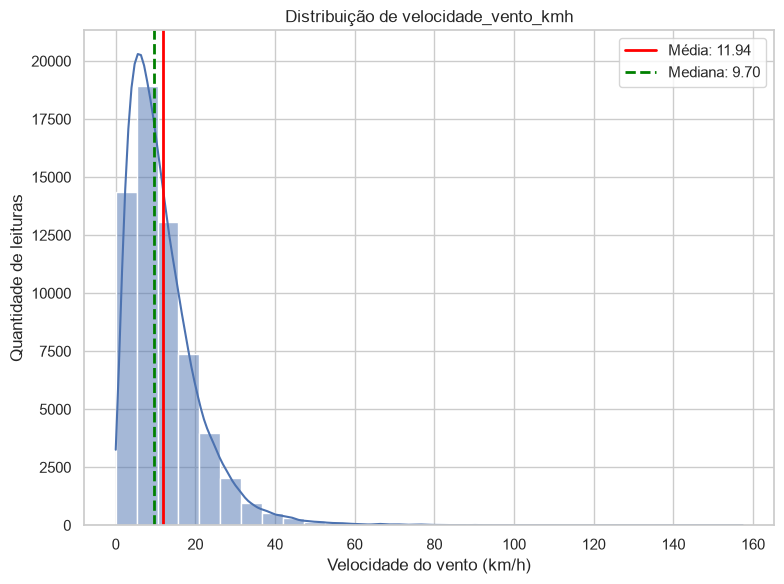

In [20]:
# Histograma: como os valores se distribuem, com a curva da distribuição e as linhas de média e mediana.
sns.histplot(serie_numerica.dropna(), bins=30, kde=True)
plt.axvline(serie_numerica.mean(), color="red", linestyle="-", linewidth=2, label=f"Média: {serie_numerica.mean():.2f}")
plt.axvline(serie_numerica.median(), color="green", linestyle="--", linewidth=2, label=f"Mediana: {serie_numerica.median():.2f}")
plt.title(f"Distribuição de {COLUNA_NUMERICA}")
plt.xlabel("Velocidade do vento (km/h)")
plt.ylabel("Quantidade de leituras")
plt.legend()
plt.tight_layout()
plt.show()

### Célula 20 · Boxplot

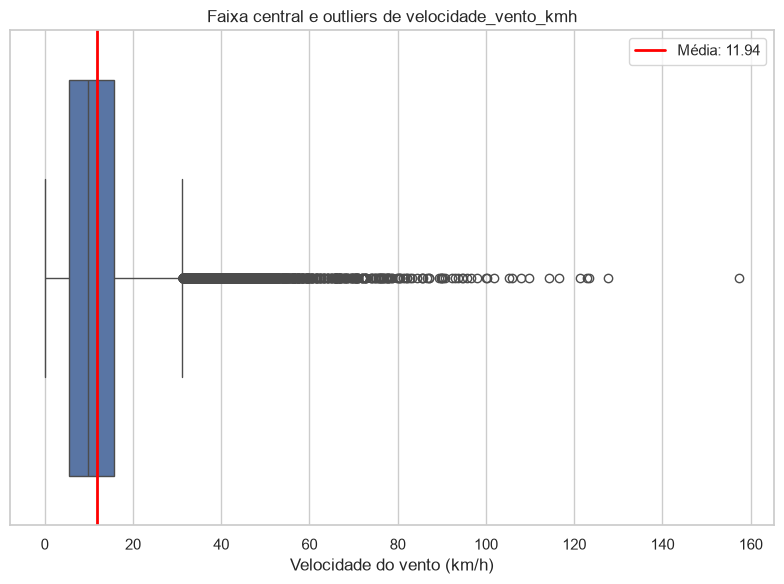

In [21]:
# Boxplot: a caixa é a faixa central (25% a 75%); os pontos fora são candidatos a outlier.
sns.boxplot(x=serie_numerica.dropna())
plt.axvline(serie_numerica.mean(), color="red", linestyle="-", linewidth=2, label=f"Média: {serie_numerica.mean():.2f}")
plt.title(f"Faixa central e outliers de {COLUNA_NUMERICA}")
plt.xlabel("Velocidade do vento (km/h)")
plt.legend()
plt.tight_layout()
plt.show()

### Célula 20 (complemento) · Boxplot por condição do tempo

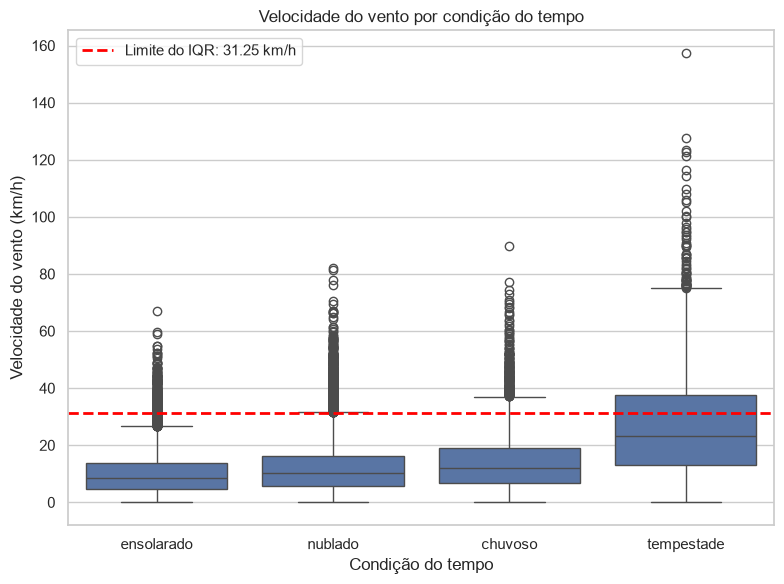

In [22]:
# Boxplot por condição do tempo, da mais calma para a mais severa, com a linha do limite de alerta.
ordem_condicoes = ["ensolarado", "nublado", "chuvoso", "tempestade"]
sns.boxplot(data=df_completo, x="condicao_tempo", y=COLUNA_NUMERICA, order=ordem_condicoes)
plt.axhline(limite_superior, color="red", linestyle="--", linewidth=2, label=f"Limite do IQR: {limite_superior:.2f} km/h")
plt.title("Velocidade do vento por condição do tempo")
plt.xlabel("Condição do tempo")
plt.ylabel("Velocidade do vento (km/h)")
plt.legend()
plt.tight_layout()
plt.show()

### Leitura dos gráficos

No histograma dá para ver que a maior parte das leituras fica abaixo de 25 km/h e que existe uma cauda comprida para a direita, por isso a linha da média (vermelha) fica depois da mediana (verde). No boxplot por condição, a caixa da `tempestade` fica bem acima das outras, e a parte de cima dela (o 3º quartil, perto de 38 km/h) já passa do limite de 31,25 km/h. Os gráficos mostram o mesmo que a recomendação: alertar pelo limite de velocidade e ficar de olho nas tempestades.